# 02 · 小型 Transformer 遮蔽表達值重建

任務：人為遮住一部分已知的 **normalize-total + log1p 表達值**，用同一細胞其餘基因預測這些位置。這是學習用 reconstruction，不是真實缺失訊號的生物學 imputation。

先比較「train 各基因平均值」基準，再訓練 128 genes、embedding 32、4 heads、1 層 Encoder 的小模型。這裡會真的執行 5 epochs，並保存所有結果。

In [1]:
from pathlib import Path
import os
import sys

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
assert (ROOT / "pyproject.toml").exists(), "請從專案根目錄或 notebooks/ 啟動"
sys.path.insert(0, str(ROOT))
for key, folder in [("MPLCONFIGDIR", "matplotlib"), ("NUMBA_CACHE_DIR", "numba"), ("XDG_CACHE_HOME", "")]:
    os.environ.setdefault(key, str(ROOT / ".cache" / folder))

import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from IPython.display import display, Image
from singlecell_baseline.data import DataConfig, load_pbmc3k, quality_control

FIGURES = ROOT / "outputs" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
config = DataConfig()
from importlib.metadata import version
print("Python:", sys.version.split()[0], "Scanpy:", version("scanpy"))

import torch
from singlecell_baseline.data import prepare_data, save_prepared
from singlecell_baseline.model import ExpressionTransformer, make_mask, masked_input, masked_mse
from singlecell_baseline.train import TrainConfig, run_training, load_checkpoint, predict
print("PyTorch:", torch.__version__, "MPS available:", torch.backends.mps.is_available())

Python: 3.11.2 Scanpy: 1.11.5


PyTorch: 2.14.1 MPS available: True


## 1. 重新讀 counts，先切分細胞

使用 70% / 15% / 15% 的隨機細胞切分（整數數量因 rounding 略有差異）。QC 門檻固定，每個細胞獨立處理。

基因的最低偵測細胞數、HVG 排名、平均值，都只用 train 決定；validation/test 沿用相同順序。每個細胞用自己的完整 library 總量正規化，再取 log1p，然後才取 128 個基因。沒有使用全資料探索的 HVG／PCA／UMAP。

這是對已完整量測並預處理的向量做人工遮蔽；正規化在遮蔽前完成，不能解讀為在原始 counts 缺失的情境重建。

In [2]:
raw = load_pbmc3k(ROOT / "data" / "raw")
prepared = prepare_data(raw, DataConfig(n_genes=128, seed=42))
save_prepared(prepared, ROOT / "outputs", ROOT / "data" / "processed")
display(pd.DataFrame(prepared.report["steps"]))
print("切分:", prepared.report["split_sizes"])
display(prepared.adata.var[["train_dispersion_norm", "train_detected_cells", "train_mean"]].head())

,stage,cells,genes
0,raw counts,2700,32738
1,fixed cell QC,2638,32738
2,train-only detected gene filter,1846,12953
3,train-only HVGs / log1p target,2638,128


切分: {'train': 1846, 'validation': 396, 'test': 396}


,train_dispersion_norm,train_detected_cells,train_mean
index,,,
GBGT1,8.342110,23,0.023103
MTIF2,8.057434,41,0.038879
LRRIQ3,7.905885,5,0.006241
LINC00662,7.376931,37,0.036613
CDKN2A,7.178326,17,0.017501


## 2. Tensor、target 與遮蔽位置

一個 batch 是 `(batch_size, gene_count)`。每列隨機遮住約 15% 基因，包含零值；128 個基因實際遮住 19 個。input 的遮蔽值會清成 0，但額外的 bool mask 讓模型能區分「觀測到的 0」與「被遮住」。target 保留在另一份 Tensor，loss 只看 mask=True。

訓練每個 batch 重新抽 mask，validation/test 用 seed 43/44 固定位置。

In [3]:
target = torch.from_numpy(prepared.values("train")[:16])
mask = make_mask(tuple(target.shape), fraction=.15, seed=42)
visible = masked_input(target, mask)
print("target:", tuple(target.shape), "input:", tuple(visible.shape), "mask:", tuple(mask.shape))
assert torch.all(visible[mask] == 0)
print("每個細胞遮住的基因數:", mask.sum(dim=1).tolist())
display(pd.DataFrame({"gene": prepared.adata.var_names[:12], "target": target[0, :12],
                      "input": visible[0, :12], "masked": mask[0, :12]}))

target: (16, 128) input: (16, 128) mask: (16, 128)
每個細胞遮住的基因數: [19, 19, 19, 19, 19, 19, 19, 19, 19, 19, 19, 19, 19, 19, 19, 19]


,gene,target,input,masked
0,GBGT1,0.0,0.0,True
1,MTIF2,0.0,0.0,True
2,LRRIQ3,0.0,0.0,False
3,LINC00662,0.0,0.0,True
4,CDKN2A,0.0,0.0,False
5,BACE2,0.0,0.0,False
6,LINC00886,0.0,0.0,False
7,FAM98A,0.0,0.0,False
8,NAPA-AS1,0.0,0.0,True
9,ZNF561,0.0,0.0,False


## 3. 從輸入走過模型，再做一次梯度更新

`gene_embedding` 表示基因身分，`value_mask_encoding` 表示表達值與遮蔽標記。相加後的 token 是 `(B, G, D)`，經雙向 self-attention 與 prediction head 後成為 `(B, G)`。

沒有 positional encoding，也不使用文字生成的 causal mask。基因順序只是 vocabulary 對應，不能解讀成自然語言詞序。

模型以 train gene mean 為起點，學習 context-dependent residual：`prediction = gene_mean + head(encoder(tokens))`。head 從零開始，所以 epoch 0 正好等於平均值基準。下面的 demo 模型只用來學習，正式實驗會重新設定 seed 並建立模型。

In [4]:
torch.manual_seed(42)
demo = ExpressionTransformer(128, d_model=32, n_heads=4, n_layers=1)
demo.gene_mean.copy_(torch.from_numpy(prepared.values("train").mean(axis=0)))
optimizer = torch.optim.AdamW(demo.parameters(), lr=.001)
optimizer.zero_grad(set_to_none=True)
prediction = demo(visible, mask)
loss = masked_mse(prediction, target, mask)
loss.backward()
optimizer.step()
print("gene embeddings:", tuple(demo.gene_embedding.weight.shape))
print("value/mask:", tuple(torch.stack([visible, mask.float()], dim=-1).shape))
print("tokens / encoder output:", (16, 128, 32))
print("prediction:", tuple(prediction.shape), "masked MSE:", loss.item())

gene embeddings: (128, 32)
value/mask: (16, 128, 2)
tokens / encoder output: (16, 128, 32)
prediction: (16, 128) masked MSE: 0.05437453091144562


## 4. 正式訓練與 validation 選擇

以 AdamW、learning rate 0.001、batch size 16 跑 5 epochs。每個 epoch 先訓練，再 `eval()` / `no_grad()` 評估固定 validation mask。選擇最低 validation MSE 的權重，包含 epoch 0；如果訓練沒有改善，會如實保留 epoch 0。

test 只在選定權重後評估。曲線的 train mask 每輪不同，所以 train 與 validation 曲線不是完全相同抽樣條件。

Epoch 01/5: train MSE=0.0684, val MSE=0.0559


Epoch 02/5: train MSE=0.0683, val MSE=0.0559


Epoch 03/5: train MSE=0.0705, val MSE=0.0559


Epoch 04/5: train MSE=0.0732, val MSE=0.0571


Epoch 05/5: train MSE=0.0646, val MSE=0.0561


選定 epoch: 0 參數數: 12769


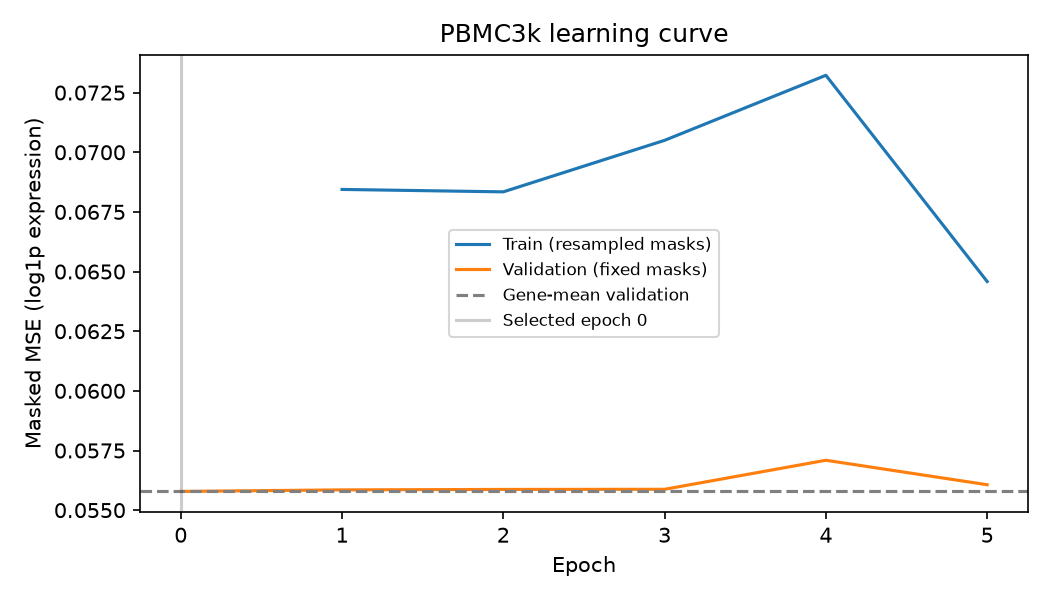

In [5]:
training_config = TrainConfig(epochs=5, batch_size=16, seed=42, device="cpu")
result = run_training(prepared, training_config, ROOT / "outputs")
print("選定 epoch:", result["best_epoch"], "參數數:", result["parameters"])
from IPython.display import Image
display(Image(filename=str(FIGURES / "learning_curve.png")))

## 5. 與平均值基準公平比較

兩個模型用完全相同的 split、targets 和 masks。MAE／RMSE 越低越好，單位是處理後的 log1p 表達值。分別查看所有遮蔽值、原本為零、原本非零三組；不能只看被大量零值主導的整體指標。

不因 test 分數調整超參數。這是單一小資料集的細胞切分，不能當成跨 donor／跨資料集泛化證據。

In [6]:
evaluation = pd.read_csv(ROOT / "outputs" / "metrics" / "evaluation.csv")
display(evaluation)
test_all = evaluation.query("split == 'test' and subset == 'all'").set_index("model")
improvement = 100 * (1 - test_all.loc["transformer", "rmse"] / test_all.loc["gene_mean", "rmse"])
print(f"此固定 test mask 的整體 RMSE 相對改善: {improvement:.2f}%（負值表示較差）")

,split,model,subset,n,mae,rmse
0,validation,gene_mean,all,7524,0.064611,0.236187
1,validation,gene_mean,zero,7374,0.033566,0.038928
2,validation,gene_mean,nonzero,150,1.590786,1.650347
3,validation,transformer,all,7524,0.064611,0.236187
4,validation,transformer,zero,7374,0.033566,0.038928
5,validation,transformer,nonzero,150,1.590786,1.650347
6,test,gene_mean,all,7524,0.066361,0.250510
7,test,gene_mean,zero,7376,0.033832,0.039179
8,test,gene_mean,nonzero,148,1.687506,1.764610
9,test,transformer,all,7524,0.066361,0.250510


此固定 test mask 的整體 RMSE 相對改善: 0.00%（負值表示較差）


## 6. 重新載入並重現預測

checkpoint 同時保存模型設定、依序排列的 gene vocabulary、前處理設定與 train gene means。載入時必須保持同樣基因順序與表達值處理。

下面驗證重新載入的權重產生相同預測；正式 training 函式也已比較保存前後的 test 預測。可閱讀 `singlecell_baseline/model.py` 與 `train.py` 進一步理解 forward、backward、optimizer 與 validation。

In [7]:
checkpoint_path = ROOT / "outputs" / "checkpoints" / "best.pt"
restored, checkpoint = load_checkpoint(checkpoint_path)
assert checkpoint["genes"] == prepared.adata.var_names.tolist()
val_target = torch.from_numpy(prepared.values("validation")[:4])
val_mask = make_mask(tuple(val_target.shape), .15, seed=43)
with torch.no_grad():
    first = restored(val_target, val_mask)
    second_model, _ = load_checkpoint(checkpoint_path)
    torch.testing.assert_close(first, second_model(val_target, val_mask), rtol=0, atol=0)
print("Checkpoint 重新載入一致:", result["checkpoint_reload_identical"])
print("validation batch prediction shape:", tuple(first.shape))

Checkpoint 重新載入一致: True
validation batch prediction shape: (4, 128)
